## Bank Marketing Prediction

In [3]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

In [4]:
DATA_PATH = Path("../data/raw/bank_marketing.csv")

df = pd.read_csv(DATA_PATH)


## Data Information

In [5]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [11]:
print("Shape:", df.shape)

df.sample(3)

Shape: (11162, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
8258,58,retired,married,secondary,no,5435,yes,no,unknown,6,may,118,1,-1,0,unknown,no
8193,47,services,married,secondary,no,0,yes,no,telephone,9,jul,250,1,-1,0,unknown,no
9474,40,management,married,tertiary,no,7780,no,no,telephone,4,may,364,1,355,1,other,no


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        11162 non-null  int64
 1   job        11162 non-null  str  
 2   marital    11162 non-null  str  
 3   education  11162 non-null  str  
 4   default    11162 non-null  str  
 5   balance    11162 non-null  int64
 6   housing    11162 non-null  str  
 7   loan       11162 non-null  str  
 8   contact    11162 non-null  str  
 9   day        11162 non-null  int64
 10  month      11162 non-null  str  
 11  duration   11162 non-null  int64
 12  campaign   11162 non-null  int64
 13  pdays      11162 non-null  int64
 14  previous   11162 non-null  int64
 15  poutcome   11162 non-null  str  
 16  deposit    11162 non-null  str  
dtypes: int64(7), str(10)
memory usage: 1.4 MB


In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,11162.0,41.231948,11.913369,18.0,32.0,39.0,49.00,95.0
balance,11162.0,1528.538524,3225.413326,-6847.0,122.0,550.0,1708.00,81204.0
day,11162.0,15.658036,8.420740,1.0,8.0,15.0,22.00,31.0
duration,11162.0,371.993818,347.128386,2.0,138.0,255.0,496.00,3881.0
campaign,11162.0,2.508421,2.722077,1.0,1.0,2.0,3.00,63.0
pdays,11162.0,51.330407,108.758282,-1.0,-1.0,-1.0,20.75,854.0
previous,11162.0,0.832557,2.292007,0.0,0.0,0.0,1.00,58.0


## Missing Values

In [13]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64

## Duplicate Records

In [20]:
duplicates = df.duplicated().sum()

print(f"Duplicate Rows : {duplicates}")

Duplicate Rows : 0


## Unique Values

In [21]:
df.nunique().sort_values()

housing         2
loan            2
default         2
deposit         2
contact         3
marital         3
poutcome        4
education       4
month          12
job            12
day            31
previous       34
campaign       36
age            76
pdays         472
duration     1428
balance      3805
dtype: int64

## Target Distribution

In [15]:
df["deposit"].value_counts()
df["deposit"].value_counts(normalize=True) * 100

deposit
no     52.616019
yes    47.383981
Name: proportion, dtype: float64

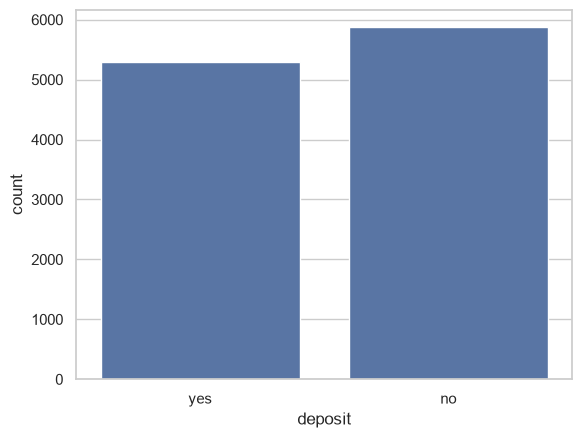

In [16]:
sns.countplot(data=df, x="deposit")
plt.show()

## Numerical Columns

In [23]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

numerical_columns

['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

## Categorical Columns

In [24]:
categorical_columns = df.select_dtypes(
    exclude=np.number
).columns.tolist()

categorical_columns

['job',
 'marital',
 'education',
 'default',
 'housing',
 'loan',
 'contact',
 'month',
 'poutcome',
 'deposit']

## Numerical Feature Distribution

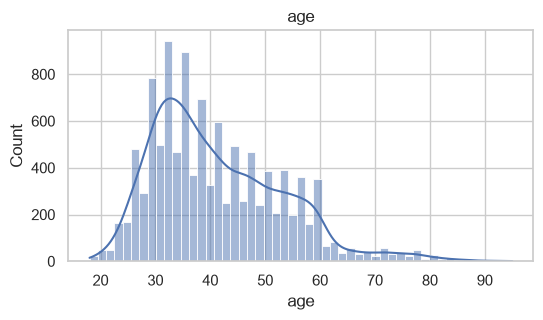

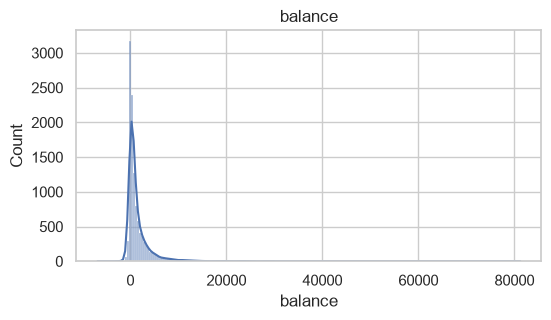

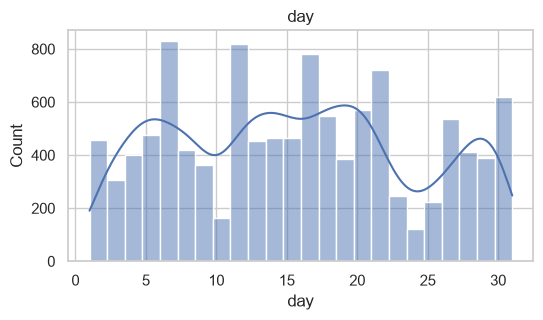

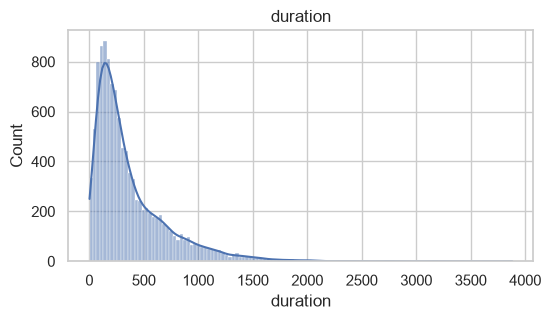

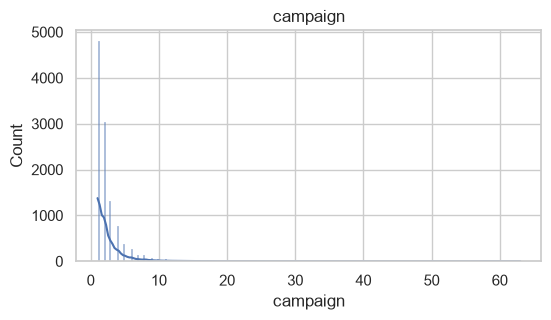

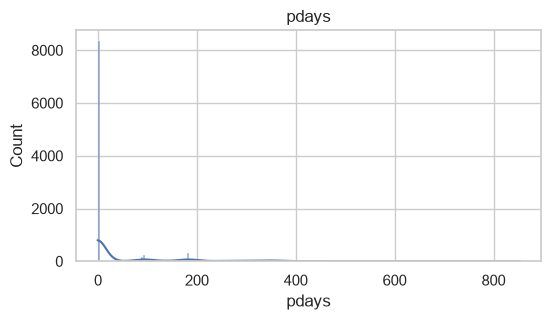

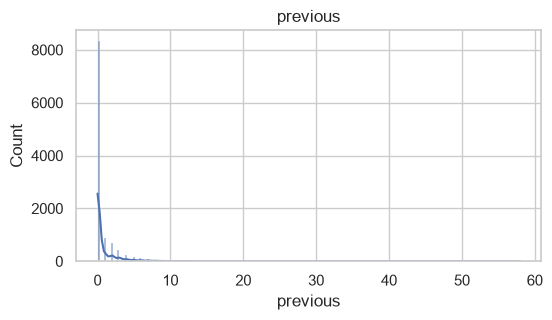

In [25]:
for column in numerical_columns:
    plt.figure(figsize=(6,3))
    sns.histplot(df[column], kde=True)
    plt.title(column)
    plt.show()

## Boxplots

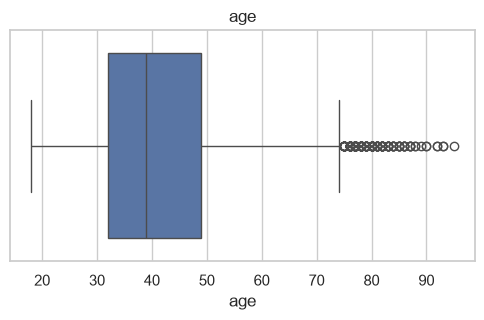

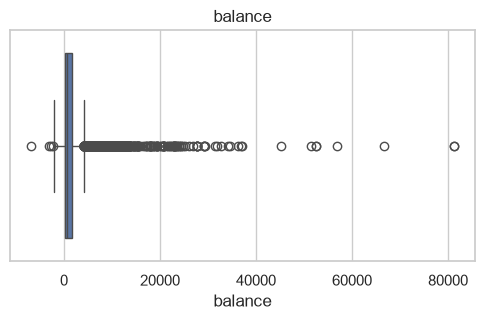

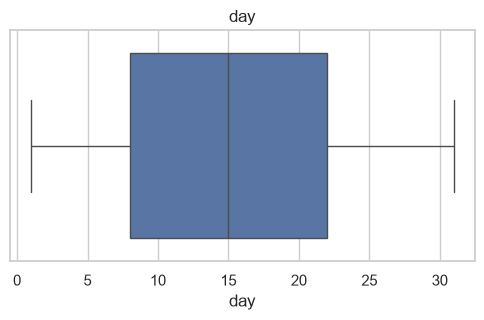

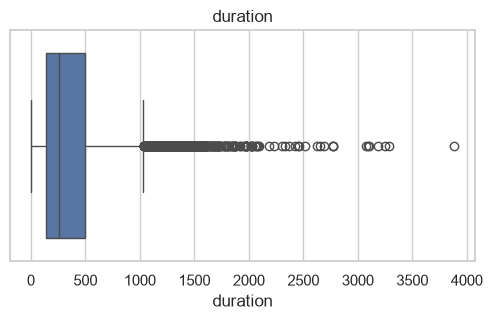

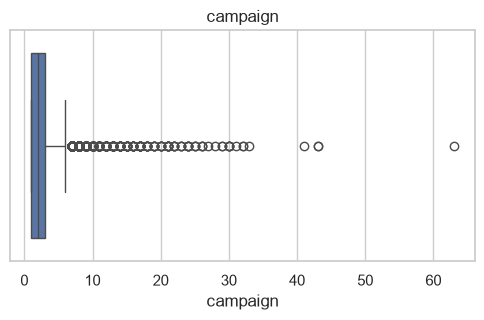

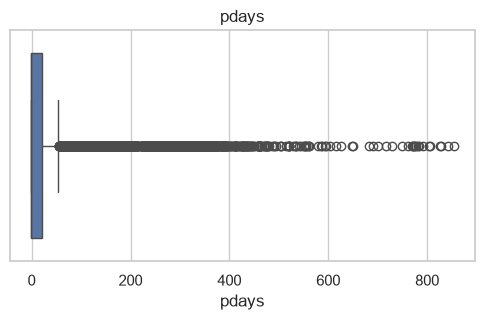

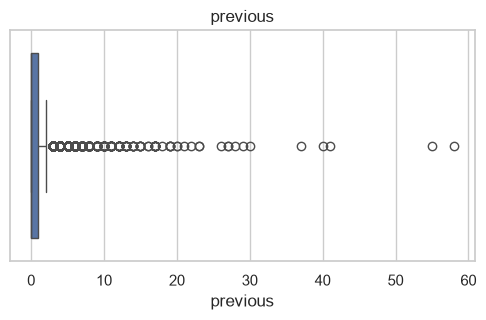

In [26]:
for column in numerical_columns:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=df[column])
    plt.title(column)
    plt.show()

## Categorical Distribution

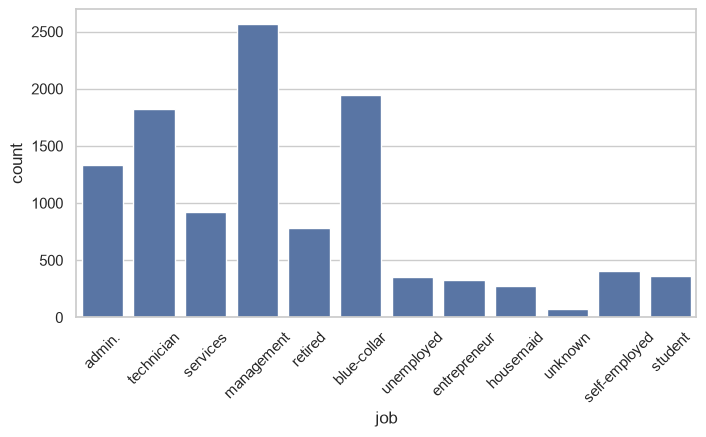

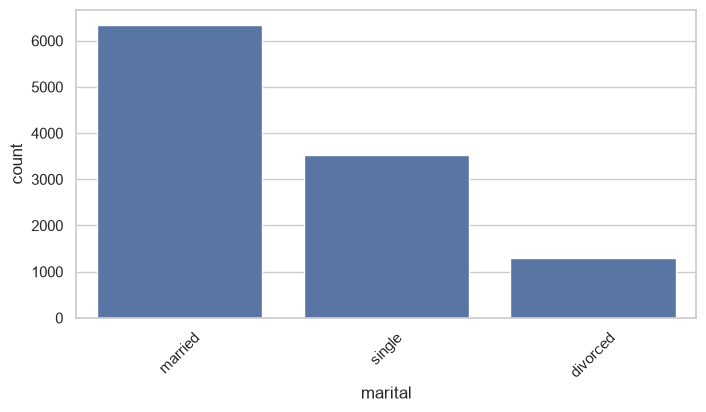

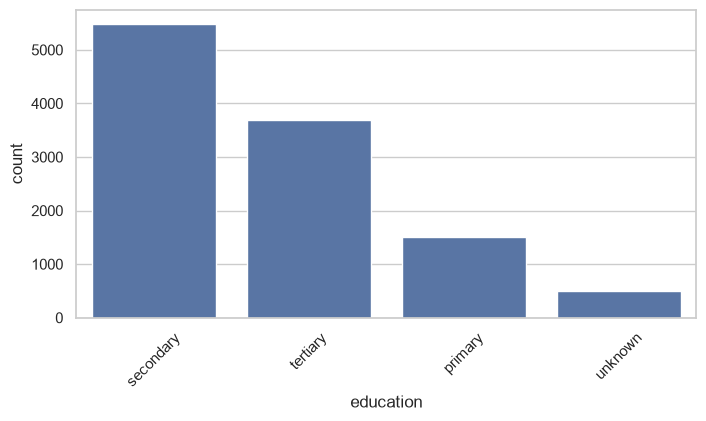

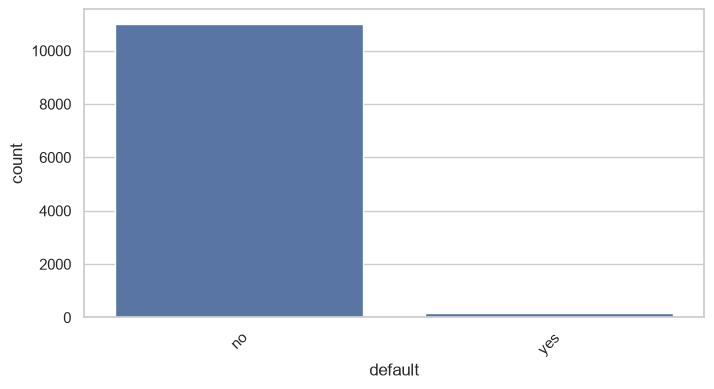

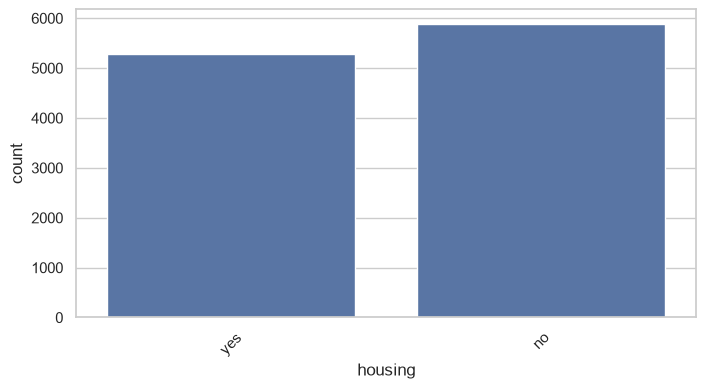

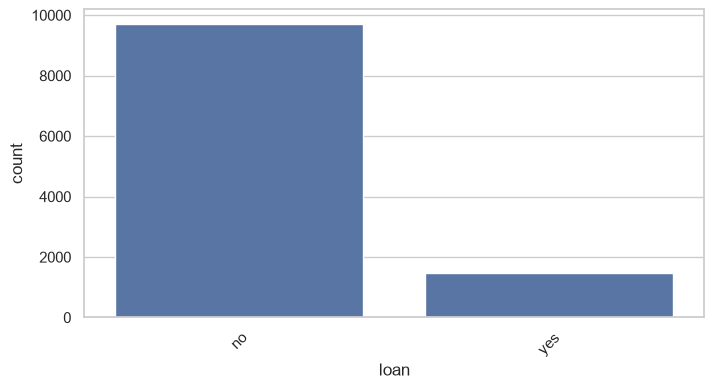

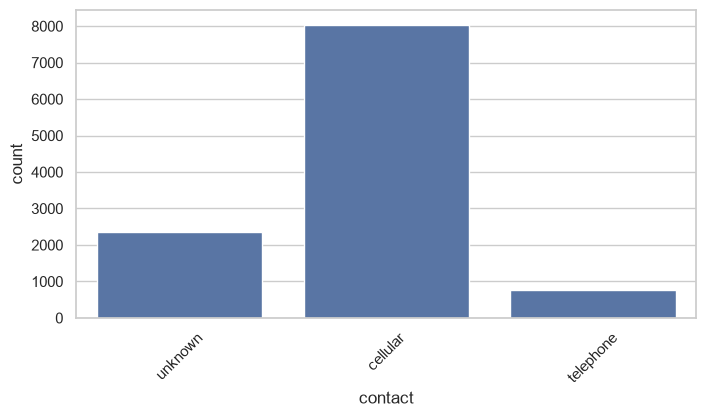

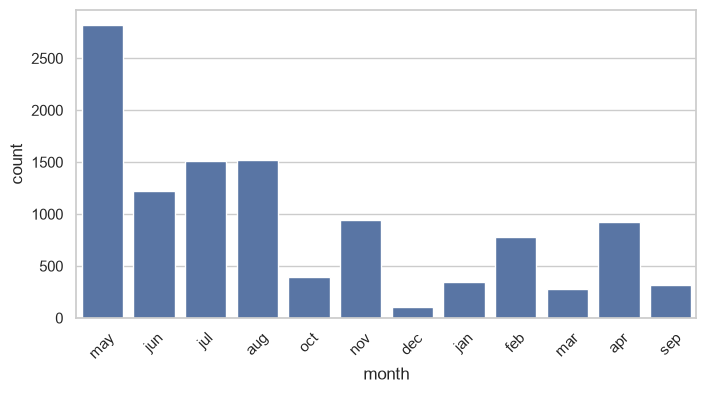

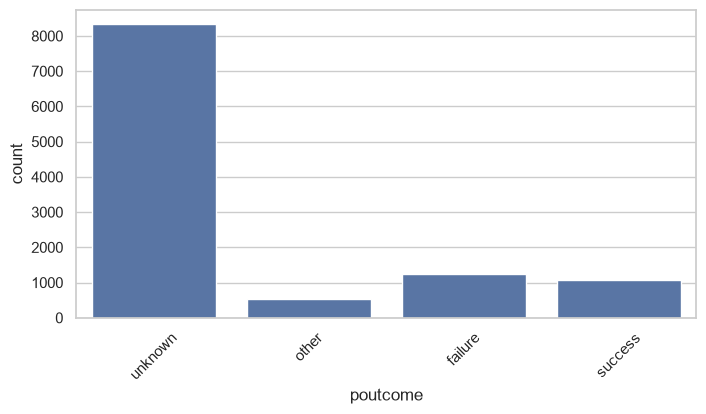

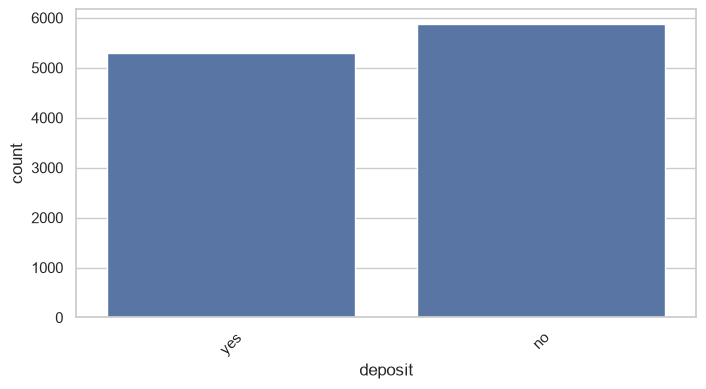

In [27]:
for column in categorical_columns:
    plt.figure(figsize=(8,4))
    sns.countplot(data=df, x=column)
    plt.xticks(rotation=45)
    plt.show()

## Correlation

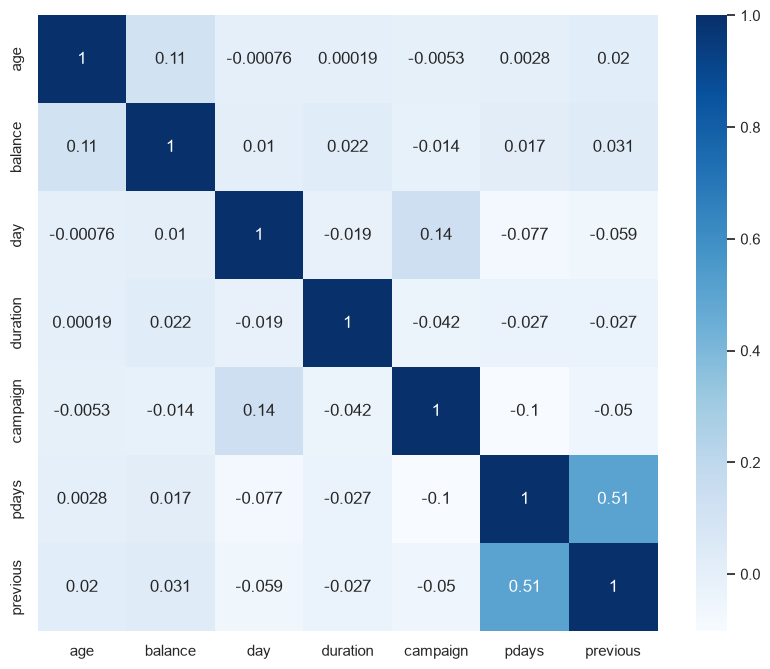

In [28]:
plt.figure(figsize=(10,8))

sns.heatmap(
    df[numerical_columns].corr(),
    annot=True,
    cmap="Blues"
)

plt.show()

## Target vs Numerical Features

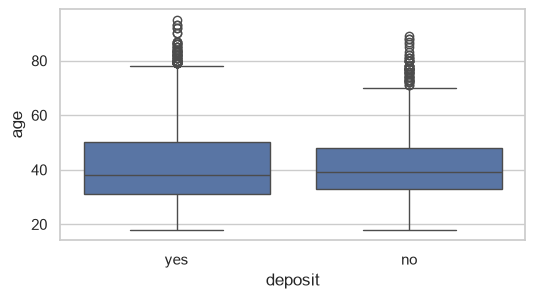

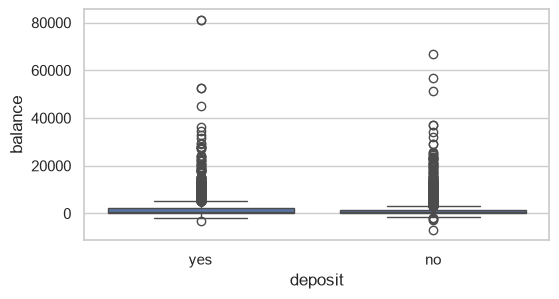

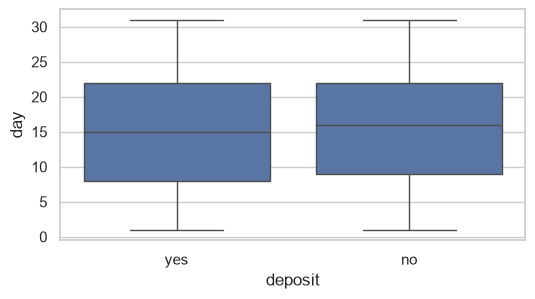

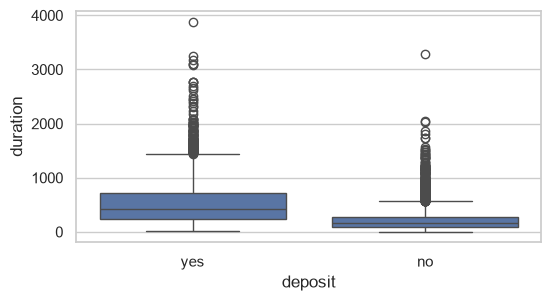

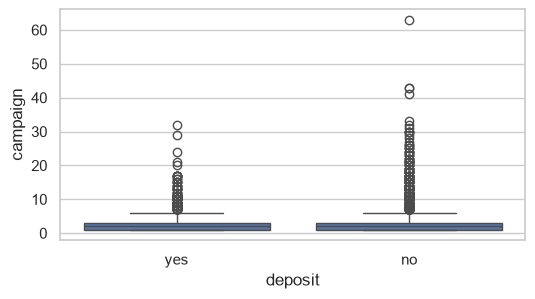

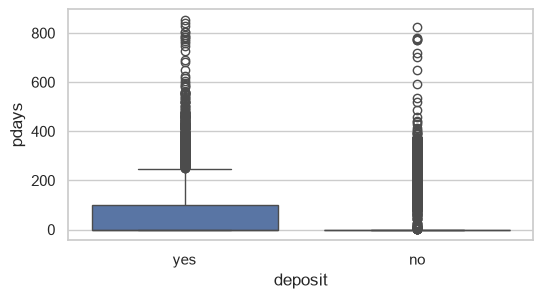

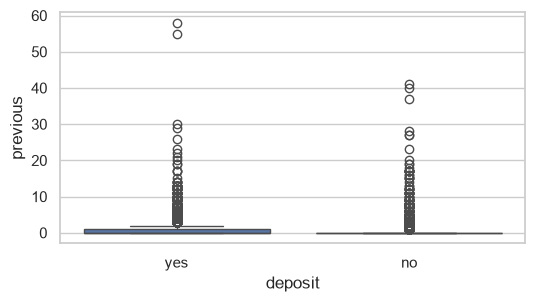

In [29]:
for column in numerical_columns:
    plt.figure(figsize=(6,3))
    sns.boxplot(data=df, x="deposit", y=column)
    plt.show()

## Target vs Categorical Features

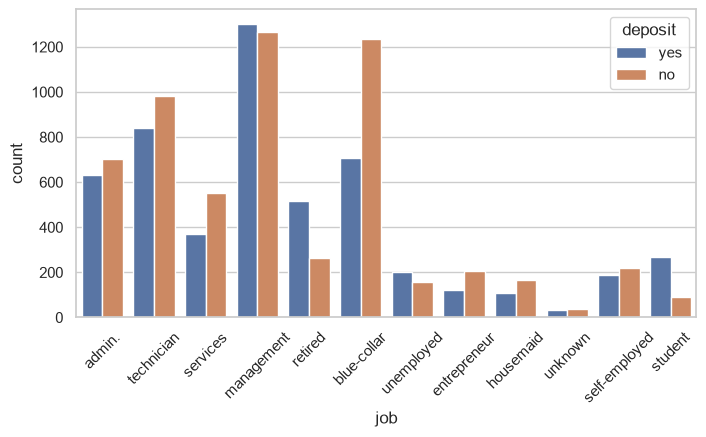

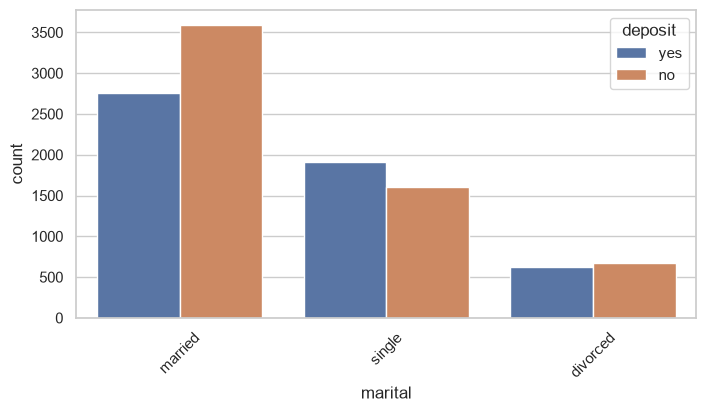

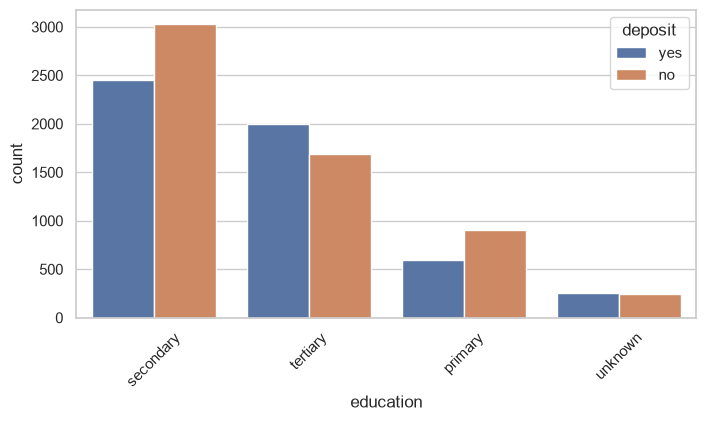

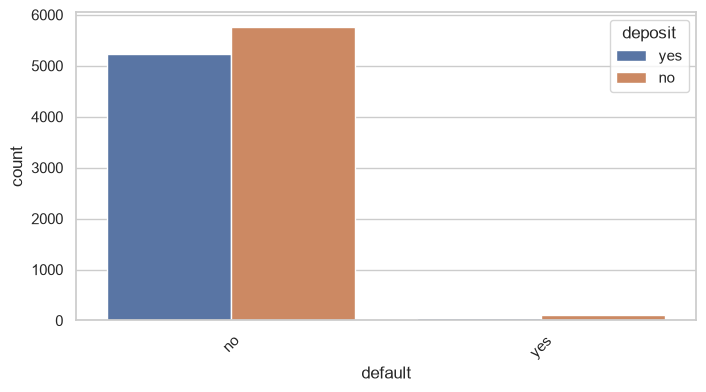

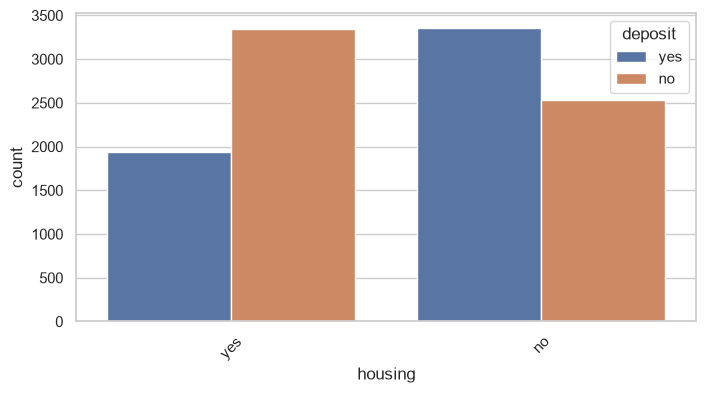

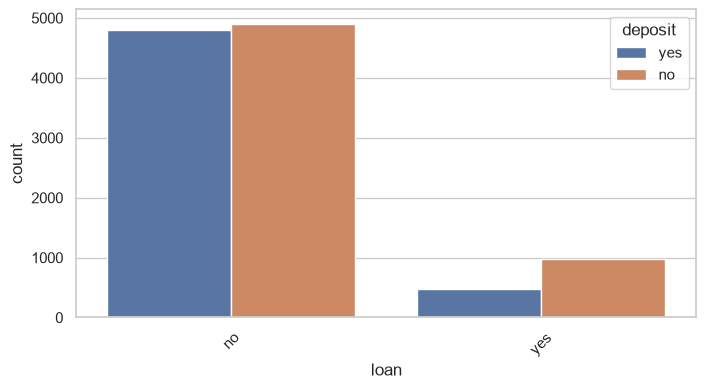

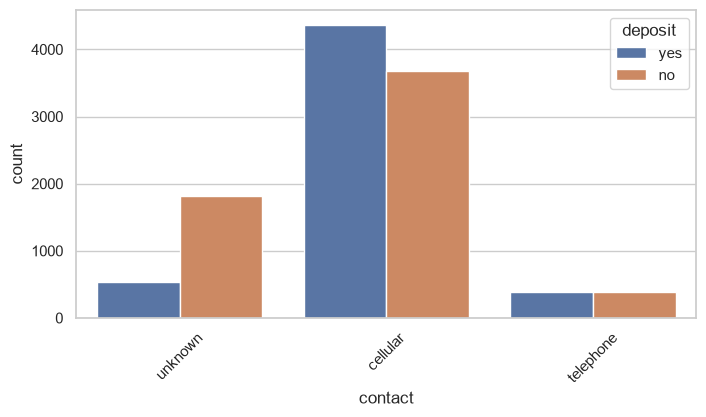

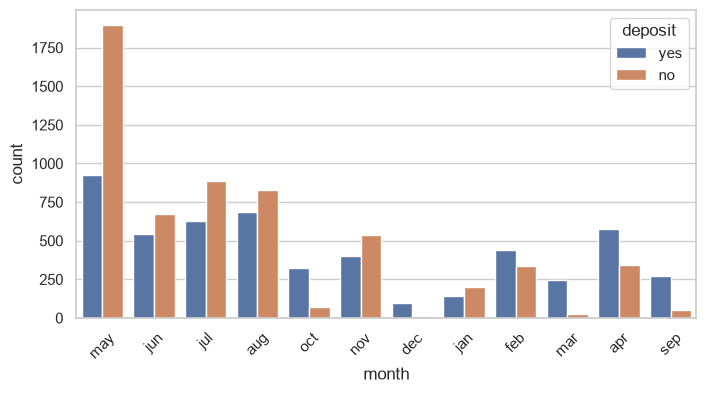

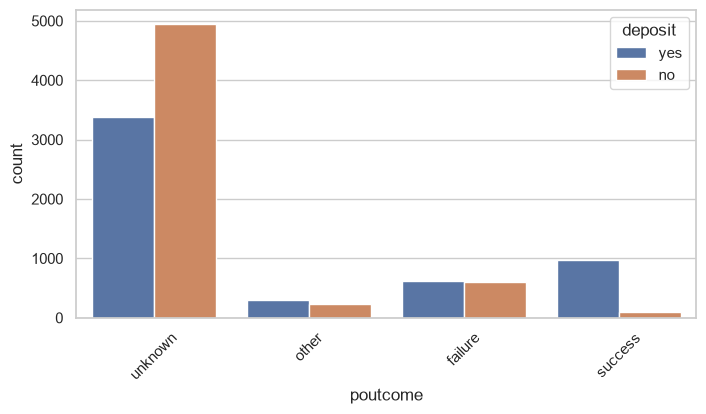

In [30]:
for column in categorical_columns:

    if column == "deposit":
        continue

    plt.figure(figsize=(8,4))

    sns.countplot(
        data=df,
        x=column,
        hue="deposit"
    )

    plt.xticks(rotation=45)
    plt.show()

## Outlier Percentage

In [31]:
for column in numerical_columns:

    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = ((df[column] < lower) | (df[column] > upper)).sum()

    print(
        f"{column}: {outliers} ({outliers/len(df)*100:.2f}%)"
    )

age: 171 (1.53%)
balance: 1055 (9.45%)
day: 0 (0.00%)
duration: 636 (5.70%)
campaign: 601 (5.38%)
pdays: 2750 (24.64%)
previous: 1258 (11.27%)
